# Solar Energy Adoption Across Australian States and Territories

**Prepared for:** Australian Renewable Energy Agency (ARENA)  
**Author:** Santhiya Nagamanickam  
**Date:** Oct 2026

**Data restrictions and organisational impact:** This report uses published small-scale solar installation data, a public postcode-to-state lookup and ABS population estimates. It contains aggregated, non-personal information and reports findings at State/Territory level. The solar series covers January 2011 to July 2025; 2025 is a part-year, and installations before 2011 are excluded. Two unmatched postcodes were removed and border postcodes were assigned to the first listed state. These limits should be considered when ARENA compares jurisdictions or allocates program effort.

## Table of Contents
1. Executive Summary
2. Introduction
3. Methodology
4. Security Measures
5. Validation Checks
6. Data Preparation
7. Normalisation
8. Analysis and Findings
9. Discussion and Recommendations
10. References
11. Appendices


## 1. Executive Summary

This report examines small-scale solar adoption across Australian states and territories using monthly postcode-level installed capacity from January 2011 to July 2025. Python, Pandas, Jupyter Notebook, openpyxl and Matplotlib were used to extract, clean, join, aggregate and visualise the data. Capacity was summarised by state and year, then normalised as watts per person to make comparisons between jurisdictions of different population sizes more meaningful.

The analysis indicates that New South Wales (NSW), Queensland (QLD) and Victoria (VIC) account for most installed capacity; these three states contributed about 79% of national new capacity in 2024. By contrast, South Australia (SA) leads on cumulative capacity per person at approximately 1,407 watts, followed by QLD at 1,256 watts. Tasmania is lowest at approximately 640 watts per person. Per-person adoption increased across all states, with a steeper rise after around 2018, while annual national additions have remained near 3 GW since 2021.

For ARENA, the results support evaluating adoption using both total capacity and population-standardised measures. Future work should investigate electricity prices, solar resources, incentives, housing characteristics and state policy settings before attributing differences to particular causes. Figures and summary statistics describe patterns; they do not establish causation.


## 2. Introduction

The Australian Renewable Energy Agency (ARENA) supports renewable energy growth and needs evidence to guide future solar projects and policy. This report analyses small-scale solar installations across Australian states and territories, using monthly installed capacity (kW) by postcode from January 2011 to July 2025.

The objectives are to (1) aggregate new and cumulative capacity by State/Territory, (2) standardise capacity by population using watts per person, and (3) describe how standardised adoption has changed over time. The analysis combines ARENA's `Solar_capacity.csv`, `australian_postcodes.csv` and `ABS_POPULATION.xlsx`. Python and Pandas were used for data handling, openpyxl for Excel input, Matplotlib for charts, and Jupyter Notebook for a reproducible workflow.

Raw totals mainly reflect the number of people living in each jurisdiction. Population standardisation provides a fairer comparison of adoption intensity, while reporting raw totals alongside the normalised measure retains information about the overall scale of installations.


## 3. Methodology

### 3.1 Data collection and extraction

Three local source files were read using Pandas. The solar file contains monthly columns and was reshaped from wide to long format, creating one row per postcode-month and extracting month and year from the period labels. The postcode lookup was reduced to postcode and state fields. The ABS population workbook was read with `header=None`; the actual header row was located by the `Year` label, and relevant year, state, local government area and population fields were retained. Local government area population totals were aggregated to State/Territory by year.

### 3.2 Analytical tools and techniques

The workflow explicitly uses **Python, Pandas and Jupyter Notebook**, with openpyxl, Matplotlib and ipywidgets. Group-by aggregation calculates annual new capacity by state. A grouped cumulative sum calculates cumulative capacity. Population-standardised measures are calculated as:

- **New watts per person** = annual new capacity (kW) × 1,000 ÷ population.
- **Cumulative watts per person** = cumulative capacity (kW) × 1,000 ÷ population.

Year-on-year cumulative growth is also calculated. The 2025 data is flagged as a part-year; 2024 is treated as the last full year. The historic 2001–2010 column is not included, so the cumulative series starts in January 2011.

### 3.3 Cleaning and processing sequence

The sequence is: load libraries and set file paths; extract relevant fields; standardise postcodes to four digits; remove duplicate postcode mappings; convert solar values to numeric; remove zero-capacity rows; identify and remove solar postcodes missing from the lookup; join solar records to states; aggregate capacity by state/year; merge population; calculate per-person measures; and create tables and charts.


## Data Collection and Organization

### 3.1 Data Access and Extraction

Three files were read from a local project folder using pandas.

- **Data Access:** ARENA's `Solar_capacity.csv` (rated power output in kW for 2,810 postcodes, monthly from January 2011 to July 2025), `australian_postcodes.csv` (postcode to state) and `ABS_POPULATION.xlsx` (ABS regional population by local government area, Table 3, persons). The solar file has no state or population fields, so the other two sources were required.
- **Data Extraction:** The solar file has one column per month, so the 175 monthly columns were reshaped to one row per postcode per month, and the month and year were extracted from the column names. Only the postcode and state columns were kept from the postcode file. In the ABS sheet the header sits below several title rows, so the row beginning "Year" was located automatically and the year, state, local government area and total persons columns were kept.

*Set-up: libraries, file paths and settings. 2025 holds data to July only, so 2024 is treated as the last full year.*

In [35]:
#Importing Libraries

import pandas as pd
import openpyxl as oxl
# graph part A,

import matplotlib.pyplot as plt
import ipywidgets as widgets
from matplotlib.ticker import FuncFormatter


In [2]:
#Setting path for 3 datasets 1. PostCode 2. Solarcapacity 3. Population over state
Base_path = 'C:/Users/Santhiya/python/source/repos/Occasion 1/'

postcode_File = Base_path + 'australian_postcodes.csv'
solar_File= Base_path + 'Solar_capacity.csv'
population_File = Base_path + 'ABS_POPULATION.xlsx'

#As 2025 has only till July, we set till 2024 as full year.
LAST_FULL_YEAR = 2024

# Keeping this as abbreviations instead of state full name.
#STATE_ORDER is a Python list holding the eight state and territory abbreviations in a fixed order. 
#The name is in capitals because that is the Python habit for a setting 
#that doesn't change while the program runs. The order runs roughly from the most populous state 
#to the least, but that's only a choice. The point is that it's always the same order.

STATE_ORDER = ["NSW", "VIC", "QLD", "SA", "WA", "TAS", "NT", "ACT"]


STATE_NAME_TO_CODE = {
    "New South Wales": "NSW",
    "Victoria": "VIC",
    "Queensland": "QLD",
    "South Australia": "SA",
    "Western Australia": "WA",
    "Tasmania": "TAS",
    "Northern Territory": "NT",
    "Australian Capital Territory": "ACT",
}


*Extract the postcode and state columns.*

In [20]:
#Loading and cleaning postcode dataset
postcode = pd.read_csv(postcode_File,dtype=str)
postcode.to_csv('australian_postcodes.csv', index=False)
clean_postcode_File = postcode[['postcode', 'state']].copy() #coping only two columns



*Load the solar file and reshape it from wide to long.*

In [24]:
#Load Solar Capacity and cleaning
SolarCapacity = pd.read_csv(solar_File,dtype=str)
SolarCapacity.to_csv('Solar_capacity.csv', index = False)
SolarCapacity.info()
clean_SolarCapacity = SolarCapacity.rename(columns={"Small Unit Postcode": "postcode"})
hist_col   = [c for c in clean_SolarCapacity.columns if c.startswith("Historic")][0]
month_cols = clean_SolarCapacity.columns[clean_SolarCapacity.columns.str.contains(r"^[A-Z][a-z]{2} ")].tolist()

 # Wide -> long: one row per postcode-month
long = clean_SolarCapacity.melt(id_vars="postcode",value_vars=month_cols,var_name="period",value_name="kw")
print(long)
long[["month_name", "year"]] = long["period"].str.extract(r"^(\w{3}) (\d{4})")
long["year"] = long["year"].astype(int)
print(long[["month_name", "year"]])

<class 'pandas.DataFrame'>
RangeIndex: 2810 entries, 0 to 2809
Columns: 178 entries, Small Unit Postcode to Total Rated Power Output In kW
dtypes: str(178)
memory usage: 3.8 MB
       postcode                               period     kw
0          0000  Jan 2011 - Rated Power Output In kW  0.000
1          0200  Jan 2011 - Rated Power Output In kW  0.000
2          0800  Jan 2011 - Rated Power Output In kW  0.000
3          0801  Jan 2011 - Rated Power Output In kW  0.000
4          0803  Jan 2011 - Rated Power Output In kW  0.000
...         ...                                  ...    ...
491745     7469  Jul 2025 - Rated Power Output In kW  1.760
491746     7470  Jul 2025 - Rated Power Output In kW  0.000
491747     7802  Jul 2025 - Rated Power Output In kW  0.000
491748     8576  Jul 2025 - Rated Power Output In kW  0.000
491749     9729  Jul 2025 - Rated Power Output In kW  0.000

[491750 rows x 3 columns]
       month_name  year
0             Jan  2011
1             Jan  2011
2   

*Load population and sum local government areas to State/Territory.*

In [30]:
#Loading and cleaning population dataset
#ABS sheet has text above the real data, so added header=None as it should not identify the real data wrongly.
raw = pd.read_excel(population_File, sheet_name="Table 3", header=None) 
#this will find the header, considering Year as the first header and the [0] - first column
#hdr = raw.index[raw[0].astype(str).str.strip() == "Year"][0]
hdr = raw.index[raw[0].str.strip() == "Year"][0]
#print(raw.iloc[hdr]) #checking 
pop = raw.iloc[hdr + 1:, [0, 2, 3, 4, raw.shape[1] - 1]].copy()
pop.columns = ["year", "state_name", "lga_code", "lga_name", "population"]
print(pop.head())

pop["state"] = pop["state_name"].map(STATE_NAME_TO_CODE)
pop = pop.dropna(subset=["state"])
pop_data= pop.groupby(["state", "year"], as_index=False)["population"].sum()

print(pop_data)
pop_data[pop_data["year"] == 2025] #checking data

    year       state_name lga_code   lga_name population
6   2001  New South Wales    10050     Albury      45265
7   2001  New South Wales    10180   Armidale      27906
8   2001  New South Wales    10250    Ballina      37856
9   2001  New South Wales    10300  Balranald       2751
10  2001  New South Wales    10470   Bathurst      35504
    state  year population
0     ACT  2001     321538
1     ACT  2002     324627
2     ACT  2003     327357
3     ACT  2004     328940
4     ACT  2005     331399
..    ...   ...        ...
195    WA  2021    2749365
196    WA  2022    2793934
197    WA  2023    2890936
198    WA  2024    2978147
199    WA  2025    3044382

[200 rows x 3 columns]


### 3.2 Data Organization

- **Data Cleaning:** Postcodes were padded to four digits (for example 0800) so they match across files. The postcode lookup was reduced to one row per postcode (3,175 postcodes) because a postcode can cover several suburbs. Solar values were converted from text to numbers (no blanks resulted) and 158,485 zero rows were removed, leaving 333,265 records. Two postcodes in the solar data (5312 and 8576, 11.84 kW in total) are not in the postcode file and were removed, leaving 333,262 records, all matched to a state.
- **Data Formatting:** Each solar record now carries postcode, kW, month, year and state. Population was summed from local government areas to State/Territory by year, and state names were converted to abbreviations (NSW, VIC, QLD, SA, WA, TAS, NT, ACT). "Other Territories" was excluded because it has no matching solar postcodes. A few border postcodes appear under more than one state, so the first listed state was used.

*Clean the postcode lookup.*

In [22]:
#print(clean_postcode_File.isnull().sum()) #cleaning postcode file
clean_postcode_File["postcode"] = clean_postcode_File["postcode"].str.zfill(4)

#drop duplicates
clean_postcode_File = clean_postcode_File.drop_duplicates("postcode")[["postcode", "state"]]
#no null values in this
print(clean_postcode_File.head())
clean_postcode_File.info()

  postcode state
0     0200   ACT
2     0800    NT
4     0801    NT
5     0803    NT
6     0804    NT
<class 'pandas.DataFrame'>
Index: 3175 entries, 0 to 18544
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   postcode  3175 non-null   str  
 1   state     3175 non-null   str  
dtypes: str(2)
memory usage: 74.4 KB


*Clean the solar values: numeric conversion and zero rows.*

In [26]:
long_solar = long.drop(columns="period")

long_solar = long_solar[long_solar["kw"] != 0.000]
print(f"Zero rows: {(long_solar['kw'] == 0.000).sum():,}")
print(long["kw"].isna().sum())
print(long["kw"].dtype) 
long_solar["kw"] = pd.to_numeric(long_solar["kw"], errors="coerce")
print(long_solar["kw"].dtype)                 # should now be float64
print(f"Blanks after conversion: {long_solar['kw'].isna().sum():,}")
print(f"Zero rows: {(long_solar['kw'] == 0).sum():,}")
long_solar = long_solar[long_solar["kw"] != 0.000]
print(f"Zero rows: {(long_solar['kw'] == 0.000).sum():,}")
print(long_solar)

Zero rows: 0
0
str
float64
Blanks after conversion: 0
Zero rows: 158,485
Zero rows: 0
       postcode     kw month_name  year
6          0810   3.02        Jan  2011
8          0812   3.00        Jan  2011
16         0830   3.02        Jan  2011
18         0832  10.52        Jan  2011
20         0835   3.00        Jan  2011
...         ...    ...        ...   ...
491739     7325  53.02        Jul  2025
491740     7330  14.52        Jul  2025
491741     7331  15.84        Jul  2025
491743     7467  13.16        Jul  2025
491745     7469   1.76        Jul  2025

[333265 rows x 4 columns]


*Find and remove postcodes missing from the postcode file.*

In [33]:
# merging Solar and postcode
#need to check missing postcode in postcode sheet. 
missing = long_solar[~long_solar["postcode"].isin(clean_postcode_File["postcode"])]
print(missing) # 8576 and 5312 not available in postcode file
#dropping those missing rows
long_solar = long_solar[long_solar["postcode"].isin(clean_postcode_File["postcode"])].reset_index(drop=True)
long_solar[long_solar["postcode"].isin(["8576", "5312"])] #now not available

      postcode    kw month_name  year
8428      8576  1.90        Mar  2011
16148     5312  5.00        Jun  2011
50578     8576  4.94        Jun  2012


,postcode,kw,month_name,year


*Join solar records to states.*

In [36]:
merged = long_solar.merge(clean_postcode_File, on="postcode", how="left")
print(merged)
unmatched = merged[merged["state"].isna()]
print(unmatched)

       postcode     kw month_name  year state
0          0810   3.02        Jan  2011    NT
1          0812   3.00        Jan  2011    NT
2          0830   3.02        Jan  2011    NT
3          0832  10.52        Jan  2011    NT
4          0835   3.00        Jan  2011    NT
...         ...    ...        ...   ...   ...
333257     7325  53.02        Jul  2025   TAS
333258     7330  14.52        Jul  2025   TAS
333259     7331  15.84        Jul  2025   TAS
333260     7467  13.16        Jul  2025   TAS
333261     7469   1.76        Jul  2025   TAS

[333262 rows x 5 columns]
Empty DataFrame
Columns: [postcode, kw, month_name, year, state]
Index: []


## 4. Security Measures

The source files were kept in one project folder and processed locally in Jupyter Notebook. The datasets used here are public or aggregated: installed capacity by postcode, published population totals and a public postcode lookup. The report presents State/Territory-level findings rather than individual records. No personal or commercially sensitive records were handled. Sources are acknowledged in the References and the data is used for the ARENA reporting scenario.

For future operational use, ARENA should apply approved access controls to project folders, retain source files separately from processed outputs, document changes and maintain versioned notebooks and data extracts.


## 5. Validation Checks

Validation was performed through checks included in the notebook workflow:

- The postcode lookup was reduced to one row per postcode and postcodes were padded to four characters to support consistent joins.
- Solar values were checked for missing values and their data type before and after numeric conversion.
- Zero-capacity rows were counted and removed.
- Solar postcodes absent from the postcode lookup were explicitly identified. The report records two unmatched postcodes (5312 and 8576), with 11.84 kW in total, which were removed.
- After joining solar data to the postcode lookup, unmatched state values were checked; the reported cleaned result contains no unmatched records.
- Population data was inspected after extraction and aggregation, including a check of 2025 records.

These checks provide evidence that the prepared dataset is internally consistent for the stated analysis. The results remain subject to the limitations listed on the title page, including the part-year 2025 data and the postcode-to-state assignment rule.


## 6. Data Preparation

The postcode data was reduced to the postcode and state columns, postcodes were padded to four digits, and duplicate postcode mappings were removed. Solar capacity was reshaped from monthly wide format into long format, numeric conversion was applied, and zero-capacity rows were removed. Two unmatched postcodes were excluded before the solar records were joined to state information. ABS local government area population values were aggregated to State/Territory and year, and state names were converted to abbreviations. “Other Territories” was excluded because it has no matching solar postcodes.

The cleaning summary recorded in the source analysis is: 158,485 zero rows removed, leaving 333,265 records before unmatched-postcode removal; two unmatched postcodes were removed, leaving 333,262 matched records. A few border postcodes can appear under more than one state, so the first listed state was used.


## 7. Normalisation

### Method and rationale

The analysis normalises installed solar capacity by population using **watts per person**. This was selected because state and territory populations differ substantially; raw capacity totals alone largely reflect jurisdiction size. Both annual new capacity and cumulative capacity are expressed per person, allowing comparison of adoption intensity and its trajectory.

### Before and after examples

| Measure | Before normalisation | After normalisation |
|---|---:|---:|
| NSW cumulative capacity to July 2025 | 7.40 GW | 861 W per person |
| NT cumulative capacity to July 2025 | 0.20 GW | 771 W per person |
| SA cumulative capacity to July 2025 | 2.68 GW | 1,407 W per person |

NSW has about 36 times the NT's capacity in total, but their per-person values are much closer. SA moves from fifth by total capacity to first by cumulative watts per person. This illustrates why ARENA should review both total scale and population-standardised adoption rather than using either measure alone.


## 8. Analysis and Findings

### Descriptive statistics and summary table

| State/Territory | Cumulative capacity (GW) | Population | Cumulative watts per person |
|---|---:|---:|---:|
| SA | 2.68 | 1,902,665 | 1,407 |
| QLD | 7.12 | 5,669,764 | 1,256 |
| ACT | 0.48 | 484,630 | 981 |
| WA | 2.92 | 3,044,382 | 960 |
| NSW | 7.40 | 8,592,524 | 861 |
| NT | 0.20 | 264,556 | 771 |
| VIC | 5.23 | 7,073,859 | 739 |
| TAS | 0.37 | 576,261 | 640 |

The highest cumulative capacity is in NSW (7.40 GW), and the lowest is in the NT (0.20 GW). The highest cumulative capacity per person is in SA (1,407 W), and the lowest is in TAS (640 W). The national average is reported as approximately 956 W per person. These are descriptive comparisons, not evidence of what caused the differences.

### Visual 1 — Annual new capacity by state

**Analysis:** The interactive chart plots annual new solar capacity in megawatts by State/Territory, with a year selector and optional log scale. In 2024, NSW, QLD and VIC contributed about 79% of national new capacity.

**Interpretation:** Annual totals are concentrated in the larger states, so this figure is most useful for understanding market scale and where the largest absolute additions occur. The log-scale option helps make smaller jurisdictions visible.

**Business implications:** ARENA can use absolute capacity to estimate the scale of potential programs, infrastructure and delivery partnerships, but should pair it with per-person indicators to avoid overlooking smaller jurisdictions.


### State/year aggregation and cumulative totals
The following cells aggregate new capacity by state and year and calculate the running cumulative total.

In [37]:

#Need to calculate annual, new_kw is group by state and year cumulative kw - 
#addition of current year and previous all years
annual = (merged.groupby(["state", "year"], as_index=False)["kw"].sum()
                    .rename(columns={"kw": "new_kw"})
                    .sort_values(["state", "year"]))
annual["cumulative_kw"] = annual.groupby("state")["new_kw"].cumsum()

In [143]:
print(annual)

    state  year      new_kw  cumulative_kw
0     ACT  2011   17345.318      17345.318
1     ACT  2012    5191.793      22537.111
2     ACT  2013   10818.678      33355.789
3     ACT  2014    6515.575      39871.364
4     ACT  2015    6853.511      46724.875
..    ...   ...         ...            ...
115    WA  2021  353317.798    1944363.998
116    WA  2022  286828.657    2231192.655
117    WA  2023  273494.216    2504686.871
118    WA  2024  285067.544    2789754.415
119    WA  2025  132369.570    2922123.985

[120 rows x 4 columns]


### Population standardisation calculations
The following cells merge annual capacity with population and calculate new and cumulative watts per person, year-on-year growth and the part-year flag.

*Standardise by population (watts per person).*

In [40]:
    out = annual.merge(pop_data, on=["state", "year"], how="left")
    out["new_w_per_capita"]        = out["new_kw"] * 1000 / out["population"]
    out["cumulative_w_per_capita"] = out["cumulative_kw"] * 1000 / out["population"]
    out["cum_yoy_growth_pct"]      = out.groupby("state")["cumulative_kw"].pct_change() * 100
    out["part_year"]               = out["year"] > LAST_FULL_YEAR

   

In [41]:
    out.tail(8)

,state,year,new_kw,cumulative_kw,population,new_w_per_capita,cumulative_w_per_capita,cum_yoy_growth_pct,part_year
112,WA,2018,210223.761,1008441.606,2617792,80.305754,385.226025,26.336640,False
113,WA,2019,246568.623,1255010.229,2659625,92.708041,471.87488,24.450461,False
114,WA,2020,336035.971,1591046.200,2712912,123.865415,586.471732,26.775556,False
115,WA,2021,353317.798,1944363.998,2749365,128.508873,707.204754,22.206633,False
116,WA,2022,286828.657,2231192.655,2793934,102.661214,798.584596,14.751798,False
117,WA,2023,273494.216,2504686.871,2890936,94.604037,866.393054,12.257759,False
118,WA,2024,285067.544,2789754.415,2978147,95.719769,936.741677,11.381365,False
119,WA,2025,132369.570,2922123.985,3044382,43.479948,959.841434,4.744847,True


### 4.2 Findings and Visualizations

Four findings follow the three requirements: aggregation (Findings 1 and 2), standardisation (Finding 3) and trends (Finding 4).

#### Finding 1: New capacity is concentrated in NSW, QLD and VIC

- **Description:** Summing postcodes to State/Territory shows that NSW, QLD and VIC add the most new capacity each year. In 2015 (shown below) QLD added about 193 MW, NSW 176 MW and VIC 149 MW, against 7 to 10 MW in the ACT, NT and TAS. In 2024 the same three states added about 79% of national new capacity (2.5 of 3.1 GW).
- **Evidence:** Figure 1 shows new capacity by state. The slider changes the year and the log-scale option makes small states visible.

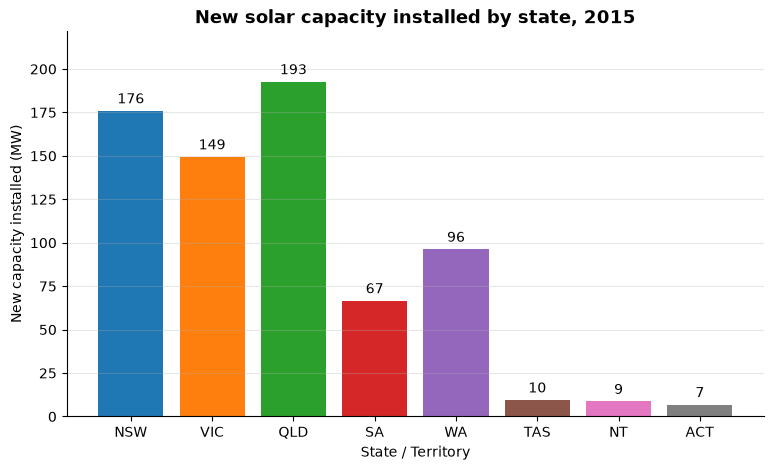

interactive(children=(SelectionSlider(description='Year', index=4, options=(np.int64(2011), np.int64(2012), np…

In [38]:

# year as slider, new_kw in y axis, state in x axis

STATE_ORDER = ["NSW", "VIC", "QLD", "SA", "WA", "TAS", "NT", "ACT"]
STATE_COLOURS = dict(zip(STATE_ORDER, plt.cm.tab10.colors))

years = sorted(annual.loc[annual["year"] >= 2011, "year"].unique())
YMAX_ALL_MW = annual.loc[annual["year"] >= 2011, "new_kw"].max() / 1000 * 1.1

def plot_new_capacity(year, same_scale_for_all_years=False, log_scale=False):
    d = (annual[annual["year"] == year]
         .set_index("state")
         .reindex(STATE_ORDER))
    mw = d["new_kw"] / 1000                                  # kW -> MW

    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.bar(mw.index, mw.values, color=[STATE_COLOURS[s] for s in mw.index])
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in mw], padding=3)

    if log_scale:
        ax.set_yscale("log")
        ax.set_ylim(1, (YMAX_ALL_MW if same_scale_for_all_years else mw.max() * 1.5) * 1.5)
    else:
        top = YMAX_ALL_MW if same_scale_for_all_years else mw.max() * 1.15
        ax.set_ylim(0, top)

    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))   # 1,000 not 1e3
    ax.set_title(f"New solar capacity installed by state, {year}", fontsize=13, weight="bold")
    ax.set_xlabel("State / Territory")
    ax.set_ylabel("New capacity installed (MW)")
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()
#can change year and see the output.
widgets.interact(
    plot_new_capacity,
    year=widgets.SelectionSlider(options=years, value=2015, description="Year"),
    same_scale_for_all_years=widgets.Checkbox(value=False, description="Same scale for all years"),
    log_scale=widgets.Checkbox(value=False, description="Log scale (see small states)"),
);

- **Interpretation:** Annual totals follow state size. Nationally, additions fell from about 1.0 GW in 2012 to 0.7 GW in 2015, then rose to about 3.1 GW a year from 2021 (3.2, 2.8, 3.1 and 3.1 GW for 2021 to 2024), so the pace of adoption has levelled off at a high level.

#### Finding 2: Installed capacity is largest in NSW and QLD

- **Description:** Cumulative capacity from January 2011 to July 2025 is highest in NSW (7.40 GW) and QLD (7.12 GW), followed by VIC (5.23 GW), WA (2.92 GW) and SA (2.68 GW). The ACT (0.48 GW), TAS (0.37 GW) and NT (0.20 GW) are far smaller. Nationally about 26.4 GW was installed.
- **Evidence:** Figure 2 ranks states by cumulative capacity.

### Visual 2 — Cumulative installed capacity by state

**Analysis:** The chart ranks cumulative small-scale solar capacity from January 2011 to July 2025. NSW (7.40 GW) and QLD (7.12 GW) are highest, followed by VIC (5.23 GW); the national total is approximately 26.4 GW.

**Interpretation:** The ranking shows where most capacity is installed, but it is strongly influenced by population size and does not alone indicate how widely solar has been adopted.

**Business implications:** Use cumulative totals to understand the scale of the installed base and potential market, while using watts per person for more equitable comparisons between states.


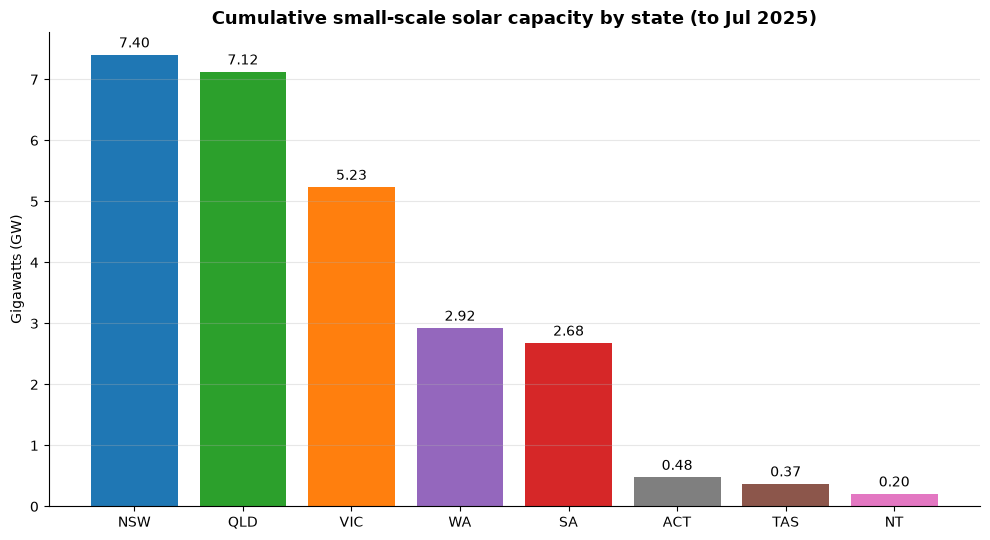

In [39]:
colours = dict(zip(STATE_ORDER, plt.cm.tab10.colors))

latest_raw = annual[annual["year"] == annual["year"].max()].set_index("state")
order = latest_raw["cumulative_kw"].sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.bar(order, latest_raw.loc[order, "cumulative_kw"] / 1e6, color=[colours[s] for s in order])   # changed: keep the bars
ax.bar_label(bars, fmt="%.2f", padding=3)                                                               # new: value on top

ax.set_title("Cumulative small-scale solar capacity by state (to Jul 2025)", fontsize=13, weight="bold")
ax.set_ylabel("Gigawatts (GW)")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

- **Interpretation:** This ranking mostly reflects population. It shows where solar is installed, not where it is most widely adopted, which is why standardisation is needed.

#### Finding 3: Per person, South Australia and Queensland lead

- **Description:** Dividing by population changes the picture. At July 2025 SA has 1,407 W per person, QLD 1,256 W, ACT 981 W, WA 960 W, NSW 861 W, NT 771 W, VIC 739 W and TAS 640 W, against a national average of about 956 W. NSW has about 36 times the NT's capacity in total, yet per person the two are close (861 W against 771 W).
- **Evidence:** Table 1 ranks states by cumulative watts per person and Figure 3 plots it.

### Visual 3 — Cumulative solar capacity per person

**Analysis:** The chart ranks cumulative watts per person. SA leads at about 1,407 W per person, followed by QLD at 1,256 W; TAS is lowest at about 640 W. The ranking differs markedly from the total-capacity ranking.

**Interpretation:** SA's shift from fifth by total capacity to first per person demonstrates the value of normalisation. NSW and VIC have large total capacity but sit below the national average per person.

**Business implications:** ARENA could investigate barriers and opportunities in lower per-person-adoption jurisdictions, while studying the sustained uptake in SA and QLD for transferable lessons. The chart should inform investigation, not be treated as proof of policy effectiveness.


In [42]:
latest = out[out["year"] == out["year"].max()].set_index("state").loc[STATE_ORDER]
ranking = latest[["cumulative_kw", "population", "cumulative_w_per_capita"]].sort_values(
    "cumulative_w_per_capita", ascending=False)
ranking

,cumulative_kw,population,cumulative_w_per_capita
state,,,
SA,2676443.819,1902665,1406.681586
QLD,7121456.612,5669764,1256.0411
ACT,475427.869,484630,981.012048
WA,2922123.985,3044382,959.841434
NSW,7400609.261,8592524,861.284677
NT,203947.579,264556,770.905135
VIC,5230973.889,7073859,739.479524
TAS,368885.426,576261,640.136025


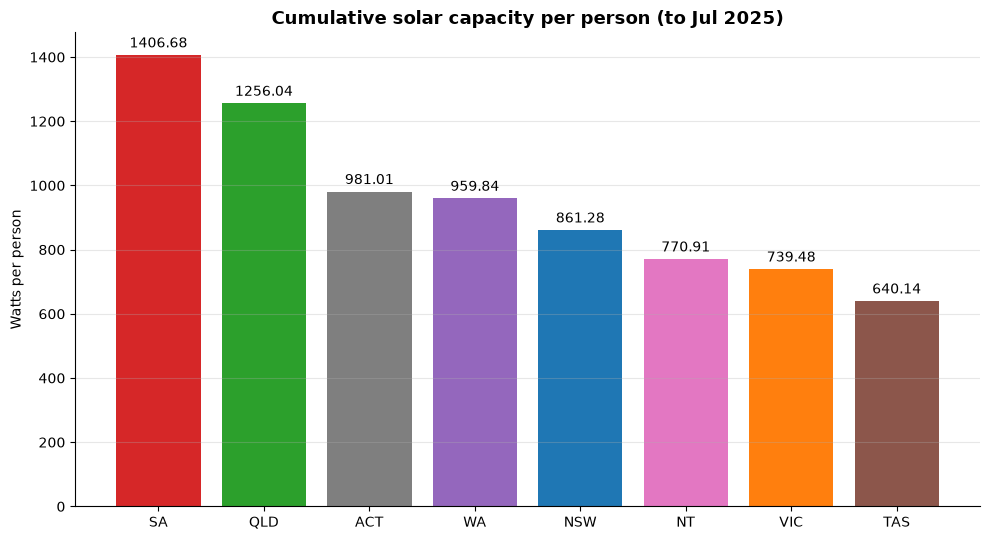

In [43]:
order = ranking.index

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.bar(order, ranking["cumulative_w_per_capita"], color=[colours[s] for s in order])
ax.bar_label(bars, fmt="%.2f", padding=3)  
ax.set_title("Cumulative solar capacity per person (to Jul 2025)", fontsize=13, weight="bold")
ax.set_ylabel("Watts per person")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

- **Interpretation:** South Australia moves from 5th by total capacity to 1st per person and the ACT from 6th to 3rd, while NSW falls from 1st to 5th and VIC from 3rd to 7th. TAS is lowest. WA and the ACT are close, so their order depends on how border postcodes and the pre-2011 base are handled.

#### Finding 4: Adoption per person has accelerated since about 2018

- **Description:** Cumulative watts per person rose in every state, and every line steepens after 2018. SA has led in every year and its lead over QLD has widened from about 50 W (2011) to about 150 W (2025). QLD has been second since 2012. The ACT climbed sharply from about 2021, moving from 7th in 2018 to 3rd by 2024. NT rose to 4th by 2018 but has slipped to 6th, and TAS has been lowest since 2019. Annual additions per person peaked between 2019 and 2023 (SA 2020; VIC, QLD and WA 2021; ACT 2022; NSW and TAS 2023; NT 2019).
- **Evidence:** Figure 4 shows cumulative watts per person for each state and for Australia.

### Visual 4 — Cumulative capacity per person over time

**Analysis:** The time-series plots cumulative watts per person by state and for Australia. All jurisdictions show growth, with steeper increases after around 2018. SA leads across the period, and the ACT rises sharply from around 2021.

**Interpretation:** The shared timing of acceleration may be consistent with national influences such as system costs, electricity prices or incentives, but these data do not test causal explanations. State-specific patterns warrant further research.

**Business implications:** ARENA should monitor per-person trends alongside annual additions and investigate the ACT's recent rise and TAS's lower rate. Linking this dataset to policy, price, solar resource, dwelling and household data could help explain the differences.


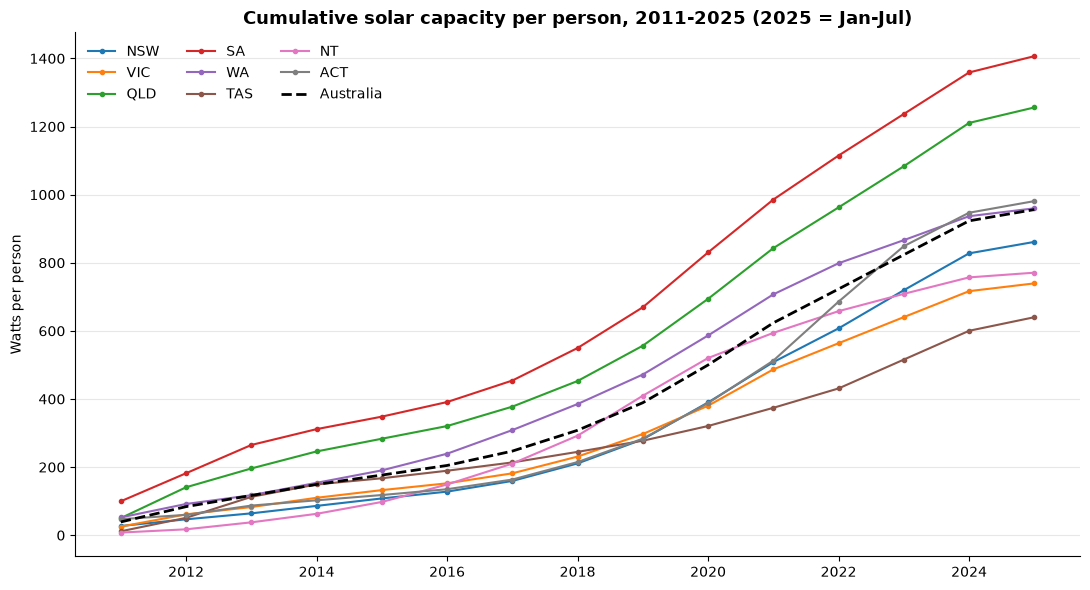

In [169]:
plot = out[out["year"] >= 2011]

fig, ax = plt.subplots(figsize=(11, 6))
for s in STATE_ORDER:
    d = plot[plot["state"] == s]
    ax.plot(d["year"], d["cumulative_w_per_capita"], marker="o", ms=3, label=s, color=colours[s])
n = nat[nat["year"] >= 2011]
ax.plot(n["year"], n["cumulative_w_per_capita"], color="k", ls="--", lw=2, label="Australia")
ax.set_title("Cumulative solar capacity per person, 2011-2025 (2025 = Jan-Jul)", fontsize=13, weight="bold")
ax.set_ylabel("Watts per person")
ax.legend(ncol=3, frameon=False)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

- **Interpretation:** All states steepen at about the same time, which points to national drivers such as falling system costs, rising electricity prices and incentives, though this data cannot show cause. The ACT's recent surge may reflect local policy and is worth investigating.

---

## 9. Discussion and Recommendations

The findings show two complementary views of solar adoption. NSW, QLD and VIC dominate total capacity and provide the largest absolute scale for projects, while SA and QLD lead on cumulative capacity per person. TAS and VIC have the lowest per-person figures in the July 2025 comparison. All states have grown over time, with a broad acceleration after around 2018 and national annual additions remaining around 3 GW since 2021.

State and territory differences may be influenced by population and dwelling mix, electricity prices, solar resource, incentives, state policy, network conditions and the timing of installations. These are plausible factors for further study, not conclusions established by this dataset. The data is limited to small-scale solar, excludes installations before 2011, covers only January–July in 2025, and applies a simplified rule for border postcodes.

**Recommendations for ARENA:**
1. Assess opportunities using both total installed capacity and watts per person.
2. Investigate lower per-person adoption in TAS and VIC, while considering local context before targeting support.
3. Examine what conditions may contribute to the sustained per-person leadership of SA and QLD.
4. Monitor whether annual national additions remain near the recent plateau and track the ACT's sharp recent rise.
5. For future projects, combine installation data with electricity prices, solar irradiance, incentives, housing/dwelling characteristics and network data.
6. Seek peer review of postcode assignment, the normalisation approach and the interpretation of state differences; document feedback and any changes in a future report.

The current analysis is descriptive and does not demonstrate causation or evaluate the effectiveness of a specific policy.


## References

- Australian Bureau of Statistics. (n.d.). *Regional population*. https://www.abs.gov.au/statistics/people/population/regional-population
- Australian Renewable Energy Agency. (n.d.). *ARENA home page*. https://arena.gov.au
- Australian postcodes lookup file (`australian_postcodes.csv`).


## Appendices

### Appendix A: Code Snippets

All code is in the executable cells in Sections 3 and 4. The two key calculations are:

```python
annual["cumulative_kw"] = annual.groupby("state")["new_kw"].cumsum()
out["cumulative_w_per_capita"] = out["cumulative_kw"] * 1000 / out["population"]
```
